<a href="https://colab.research.google.com/github/VillaArturo/Proyecto_Topicos/blob/modelo_Prueba/Modelo_automata.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
print("Análisis de sentimientos de reseñas de películas")
print("Proyecto de Rotten Tomatoes")

Análisis de sentimientos de reseñas de películas
Proyecto de Rotten Tomatoes


In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [ ]:
import pandas as pd

df = pd.read_csv('/content/sample_data/rotten_tomatoes_critic_reviews.csv')

df.head()

/tmp/ipykernel_3389/1469180997.py:3: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/sample_data/rotten_tomatoes_critic_reviews.csv')


,rotten_tomatoes_link,critic_name,top_critic,publisher_name,review_type,review_score,review_date,review_content
0,m/0814255,Andrew L. Urban,False,Urban Cinefile,Fresh,NaN,2010-02-06,A fantasy adventure that fuses Greek mythology...
1,m/0814255,Louise Keller,False,Urban Cinefile,Fresh,NaN,2010-02-06,"Uma Thurman as Medusa, the gorgon with a coiff..."
2,m/0814255,NaN,False,FILMINK (Australia),Fresh,NaN,2010-02-09,With a top-notch cast and dazzling special eff...
3,m/0814255,Ben McEachen,False,Sunday Mail (Australia),Fresh,3.5/5,2010-02-09,Whether audiences will get behind The Lightnin...
4,m/0814255,Ethan Alter,True,Hollywood Reporter,Rotten,NaN,2010-02-10,What's really lacking in The Lightning Thief i...


In [ ]:
# Mostrar la cantidad de filas y columnas
df.shape

(867434, 8)

In [ ]:
# Mostrar los nombres de las columnas
df.columns

Index(['rotten_tomatoes_link', 'critic_name', 'top_critic', 'publisher_name',
       'review_type', 'review_score', 'review_date', 'review_content'],
      dtype='object')

In [ ]:
# Contar las reseñas de cada categoría
df['review_type'].value_counts()

,count
review_type,
Fresh,551153
Rotten,316280


In [ ]:
# Revisar datos vacíos en nuestras columnas principales
df[['review_content', 'review_type']].isnull().sum()

,0
review_content,55160
review_type,1


In [ ]:
# Eliminar reseñas sin contenido
df = df.dropna(subset=['review_content'])

# Mostrar la nueva cantidad de registros
df.shape

(812274, 8)

In [ ]:
# Mostrar 5 reseñas con su clasificación
df[['review_content', 'review_type']].head()

,review_content,review_type
0,A fantasy adventure that fuses Greek mythology...,Fresh
1,"Uma Thurman as Medusa, the gorgon with a coiff...",Fresh
2,With a top-notch cast and dazzling special eff...,Fresh
3,Whether audiences will get behind The Lightnin...,Fresh
4,What's really lacking in The Lightning Thief i...,Rotten


In [ ]:
# Contar las reseñas duplicadas
df['review_content'].duplicated().sum()


np.int64(98508)

In [ ]:
# Eliminar reseñas duplicadas
df = df.drop_duplicates(subset=['review_content'])

# Mostrar la nueva cantidad de registros
df.shape

(713766, 8)

In [ ]:
# Contar nuevamente las categorías
df['review_type'].value_counts()

,count
review_type,
Fresh,455121
Rotten,258645


In [ ]:
# Convertir las categorías en valores numéricos
df['sentiment'] = df['review_type'].map({
    'Fresh': 1,
    'Rotten': 0
})

# Mostrar algunos resultados
df[['review_type', 'sentiment']].head()


,review_type,sentiment
0,Fresh,1
1,Fresh,1
2,Fresh,1
3,Fresh,1
4,Rotten,0


In [ ]:
from sklearn.model_selection import train_test_split

# Crear una muestra de 100,000 reseñas
df_muestra, _ = train_test_split(
    df,
    train_size=100000,
    stratify=df['sentiment'],
    random_state=42
)

# Mostrar la cantidad de registros
print("Total de reseñas:", len(df_muestra))
print(df_muestra['review_type'].value_counts())

Total de reseñas: 100000
review_type
Fresh     63763
Rotten    36237
Name: count, dtype: int64


In [ ]:
# Datos de entrada
X = df_muestra['review_content']

# Etiquetas de clasificación
y = df_muestra['sentiment']

# Mostrar cantidades
print("Reseñas:", len(X))
print("Etiquetas:", len(y))

Reseñas: 100000
Etiquetas: 100000


In [ ]:
from sklearn.model_selection import train_test_split

# Dividir los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Mostrar las cantidades
print("Datos de entrenamiento:", len(X_train))
print("Datos de prueba:", len(X_test))

Datos de entrenamiento: 80000
Datos de prueba: 20000


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Crear el vectorizador
vectorizador = TfidfVectorizer(
    max_features=10000,
    stop_words='english'
)

In [ ]:
# Convertir las reseñas de entrenamiento en valores numéricos
X_train_tfidf = vectorizador.fit_transform(X_train)

# Convertir las reseñas de prueba usando el mismo vectorizador
X_test_tfidf = vectorizador.transform(X_test)

# Mostrar las dimensiones de los datos
print("Entrenamiento:", X_train_tfidf.shape)
print("Prueba:", X_test_tfidf.shape)

Entrenamiento: (80000, 10000)
Prueba: (20000, 10000)


In [ ]:
from sklearn.linear_model import LogisticRegression

# Crear el modelo
modelo = LogisticRegression(max_iter=1000)


In [ ]:
# Entrenar el modelo con las reseñas de entrenamiento
modelo.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
# Realizar predicciones con los datos de prueba
y_pred = modelo.predict(X_test_tfidf)

# Mostrar las primeras 10 predicciones
print(y_pred[:10])

[1 1 1 1 1 0 1 0 1 0]


In [ ]:
from sklearn.metrics import accuracy_score

# Calcular la precisión del modelo
accuracy = accuracy_score(y_test, y_pred)

# Mostrar el resultado
print("Precisión del modelo:", accuracy)
print("Precisión en porcentaje:", accuracy * 100, "%")

Precisión del modelo: 0.78255
Precisión en porcentaje: 78.255 %


In [ ]:
from sklearn.metrics import classification_report

# Mostrar las métricas de evaluación
print(classification_report(
    y_test,
    y_pred,
    target_names=['Negativas', 'Positivas']
))

              precision    recall  f1-score   support

   Negativas       0.75      0.59      0.66      7247
   Positivas       0.79      0.89      0.84     12753

    accuracy                           0.78     20000
   macro avg       0.77      0.74      0.75     20000
weighted avg       0.78      0.78      0.78     20000



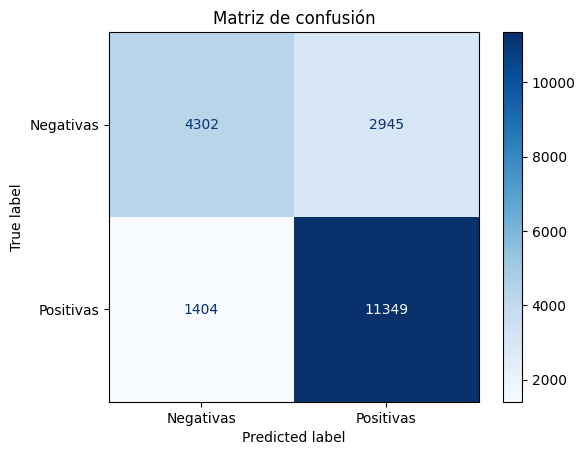

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calcular la matriz de confusión
matriz = confusion_matrix(y_test, y_pred)

# Mostrar la matriz
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=['Negativas', 'Positivas']
)

disp.plot(cmap='Blues')
plt.title('Matriz de confusión')
plt.show()

In [ ]:
# Crear reseñas nuevas para probar el modelo
reseñas_nuevas = [
    "This movie was amazing and I loved every minute.",
    "The movie was boring and a complete waste of time."
]

# Convertir las reseñas a valores numéricos
reseñas_tfidf = vectorizador.transform(reseñas_nuevas)

# Realizar las predicciones
predicciones_nuevas = modelo.predict(reseñas_tfidf)

# Mostrar los resultados
for reseña, prediccion in zip(reseñas_nuevas, predicciones_nuevas):
    sentimiento = "Positiva" if prediccion == 1 else "Negativa"
    print(reseña)
    print("Sentimiento:", sentimiento)
    print()

This movie was amazing and I loved every minute.
Sentimiento: Positiva

The movie was boring and a complete waste of time.
Sentimiento: Negativa



In [ ]:
import sys
sys.path.append('/content')
import automata_sentimientos as A
print("Automata cargado. Estados:", [e.value for e in A.Estado])

Automata cargado. Estados: ['AnalisisPolaridad', 'EstadoNeutral', 'EstadoPositivo', 'EstadoNegativo', 'Aceptacion']


In [ ]:
for r in ["This movie was amazing and I loved every minute.",
          "The movie was boring and a complete waste of time."]:
    res = A.procesar_resena(r, traza=True)
    print(r)
    print("  tokens:", res["tokens"], "->", res["sentimiento"].upper())
    for o, s, d in res["traza"]:
        print(f"    {o} --[{s}]--> {d}")

This movie was amazing and I loved every minute.
  tokens: ['amazing', 'loved', 'every', 'minute'] -> POSITIVO
    AnalisisPolaridad --[Token en diccionario (+)]--> EstadoPositivo
    EstadoPositivo --[Siguiente token]--> AnalisisPolaridad
    AnalisisPolaridad --[Token en diccionario (+)]--> EstadoPositivo
    EstadoPositivo --[Siguiente token]--> AnalisisPolaridad
    AnalisisPolaridad --[Token sin carga]--> EstadoNeutral
    EstadoNeutral --[Siguiente token]--> AnalisisPolaridad
    AnalisisPolaridad --[Token sin carga]--> EstadoNeutral
    EstadoNeutral --[Siguiente token]--> AnalisisPolaridad
    AnalisisPolaridad --[Fin de cadena]--> Aceptacion
The movie was boring and a complete waste of time.
  tokens: ['boring', 'complete', 'waste', 'time'] -> NEGATIVO
    AnalisisPolaridad --[Token en diccionario (-)]--> EstadoNegativo
    EstadoNegativo --[Siguiente token]--> AnalisisPolaridad
    AnalisisPolaridad --[Token sin carga]--> EstadoNeutral
    EstadoNeutral --[Siguiente token]-->

In [ ]:
lexico = A.entrenar_lexico(X_train, y_train)
print("Palabras positivas:", len(lexico[0]), "| negativas:", len(lexico[1]))
print("Ejemplos +:", sorted(lexico[0])[:10])
print("Ejemplos -:", sorted(lexico[1])[:10])

Palabras positivas: 1468 | negativas: 1532
Ejemplos +: ['ably', 'absolute', 'absorbing', 'acceptance', 'accessible', 'accomplished', 'accomplishment', 'account', 'acerbic', 'achievement']
Ejemplos -: ['aaliyah', 'abandons', 'abomination', 'absence', 'absurdly', 'abysmal', 'accidentally', 'actual', 'adam', 'add']


Precision del automata: 0.764
Respuestas neutral: 4223 de 20000
              precision    recall  f1-score   support

   Negativas       0.71      0.58      0.64      7247
   Positivas       0.79      0.87      0.82     12753

    accuracy                           0.76     20000
   macro avg       0.75      0.72      0.73     20000
weighted avg       0.76      0.76      0.76     20000



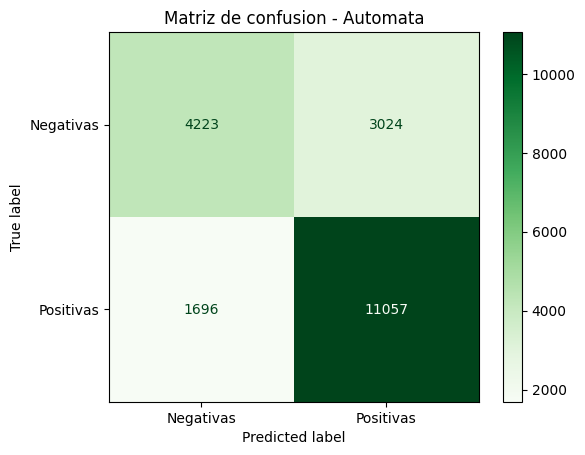

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

resultados = list(A.granja(list(enumerate(X_test)), lexico=lexico))
y_pred_automata = [0 if r["sentimiento"] == "negativo" else 1 for r in resultados]
neutrales = sum(r["sentimiento"] == "neutral" for r in resultados)

print("Precision del automata:", accuracy_score(y_test, y_pred_automata))
print("Respuestas neutral:", neutrales, "de", len(resultados))
print(classification_report(y_test, y_pred_automata, target_names=["Negativas", "Positivas"]))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_automata),
                       display_labels=["Negativas", "Positivas"]).plot(cmap="Greens")
plt.title("Matriz de confusion - Automata")
plt.show()

In [ ]:
import pandas as pd
tabla = pd.DataFrame({
    "Metodo": ["TF-IDF + Regresion Logistica", "Granja de Automatas"],
    "Precision": [accuracy_score(y_test, y_pred), accuracy_score(y_test, y_pred_automata)],
})
tabla

,Metodo,Precision
0,TF-IDF + Regresion Logistica,0.78255
1,Granja de Automatas,0.76400
